In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when viewing the dataset
pd.set_option("display.max_columns", None)

# Load the Excel dataset
df = pd.read_excel("/content/Online Retail.xlsx")

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())


First 5 rows of the dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Check the dataset size
print("Dataset shape (rows, columns):", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())


Dataset shape (rows, columns): (541909, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Number of duplicate rows: 5268


In [ ]:

# InternNova Week 4 - Task 1
# Calculate mean, median and mode for numerical columns

# Select numerical columns useful for retail analysis
columns = ["Quantity", "UnitPrice"]

for col in columns:
    print(f"\nStatistics for {col}")
    print("-" * 35)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode().iloc[0])



Statistics for Quantity
-----------------------------------
Mean: 9.55224954743324
Median: 3.0
Mode: 1

Statistics for UnitPrice
-----------------------------------
Mean: 4.611113626088513
Median: 2.08
Mode: 1.25


In [ ]:

# InternNova Week 4 - Task 2
# Calculate variance and standard deviation

columns = ["Quantity", "UnitPrice"]

for col in columns:
    print(f"\nStatistics for {col}")
    print("-" * 35)

    print("Variance:", df[col].var())
    print("Standard Deviation:", df[col].std())



Statistics for Quantity
-----------------------------------
Variance: 47559.39140913822
Standard Deviation: 218.08115784986612

Statistics for UnitPrice
-----------------------------------
Variance: 9362.469164424467
Standard Deviation: 96.75985306119716


In [ ]:

# InternNova Week 4 - Task 3
# Calculate correlation between numerical columns

correlation = df[["Quantity", "UnitPrice"]].corr()

print("Correlation Matrix:")
display(correlation)


Correlation Matrix:


,Quantity,UnitPrice
Quantity,1.000000,-0.001235
UnitPrice,-0.001235,1.000000


In [ ]:

# Calculate probability of a negative quantity
negative_quantity_count = (df["Quantity"] < 0).sum()
total_records = len(df)

probability = negative_quantity_count / total_records

print("Records with negative quantity:", negative_quantity_count)
print("Total records:", total_records)
print("Probability of negative quantity:", round(probability, 4))
print("Probability as a percentage:", round(probability * 100, 2), "%")


Records with negative quantity: 10624
Total records: 541909
Probability of negative quantity: 0.0196
Probability as a percentage: 1.96 %


In [ ]:

# InternNova Week 4 - Task 4
# Detect outliers using the Interquartile Range (IQR) method

columns = ["Quantity", "UnitPrice"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"\nOutlier Analysis for {col}")
    print("-" * 40)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))



Outlier Analysis for Quantity
----------------------------------------
Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of Outliers: 58619

Outlier Analysis for UnitPrice
----------------------------------------
Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Number of Outliers: 39627


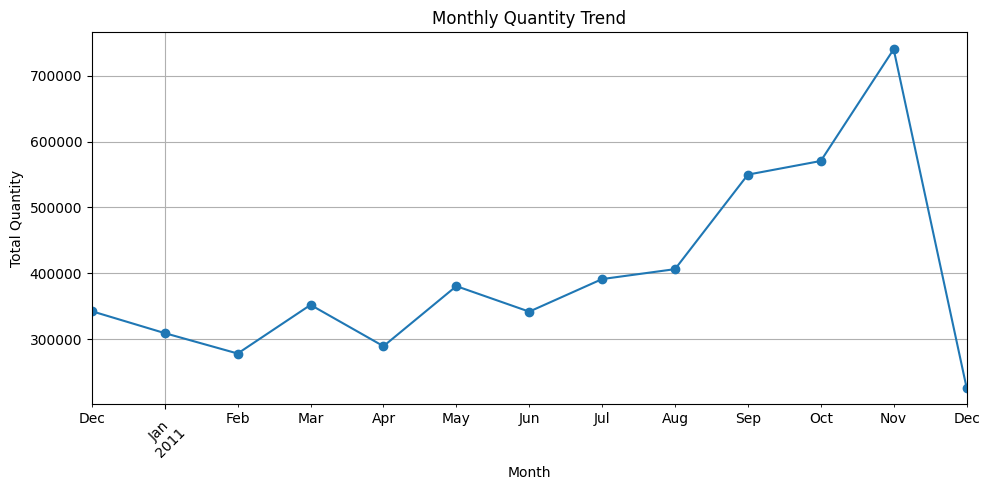

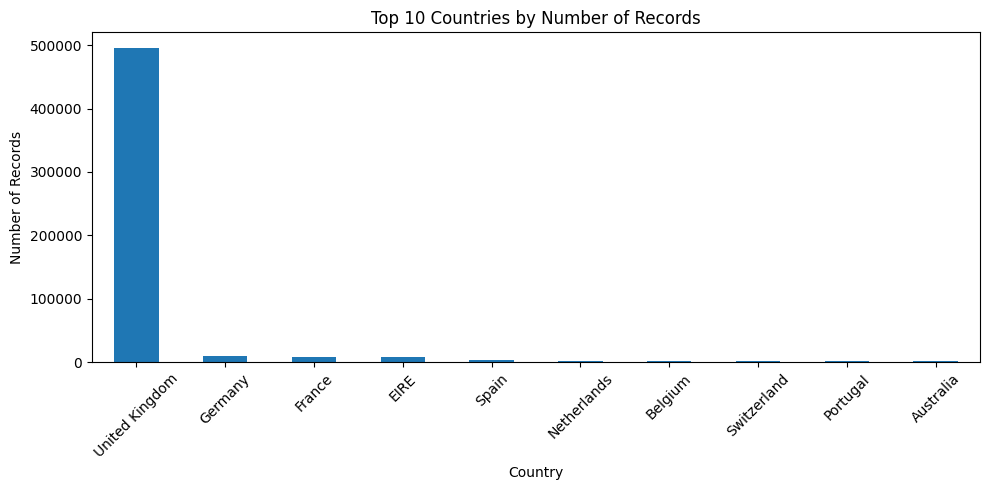

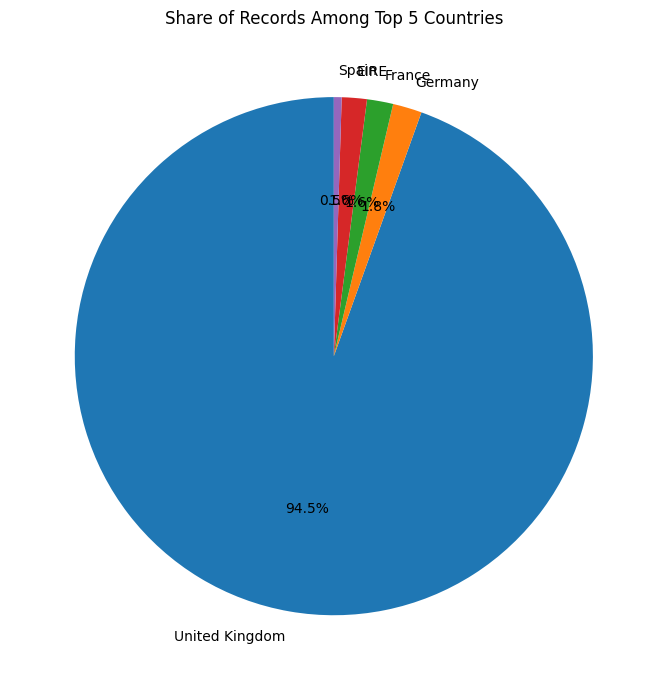

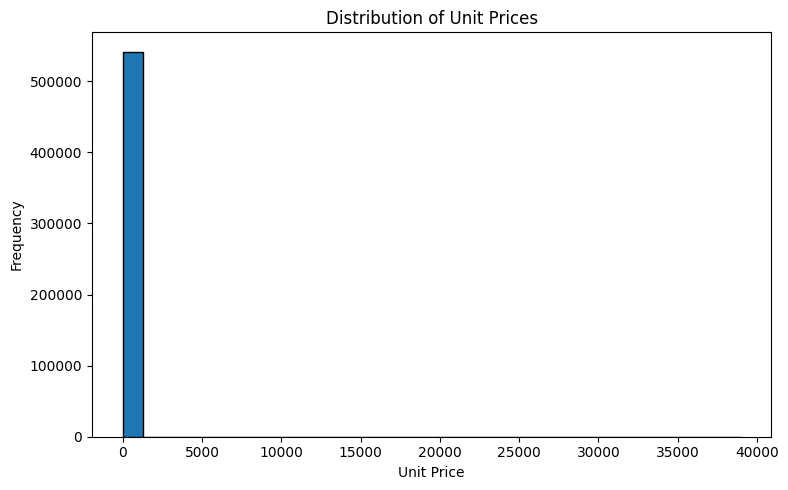

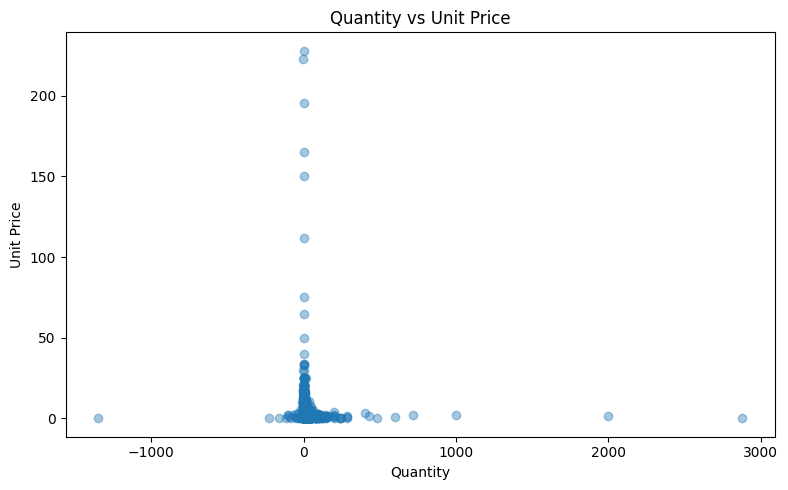

In [ ]:

# InternNova Week 4 - Task 5
# Data Visualization using Matplotlib

import matplotlib.pyplot as plt

# 1. Line Chart: Monthly sales trend
df["Month"] = df["InvoiceDate"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Quantity"].sum()

plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Quantity Trend")
plt.xlabel("Month")
plt.ylabel("Total Quantity")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# 2. Bar Chart: Top 10 countries by number of records
top_countries = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries by Number of Records")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Pie Chart: Sales records by top 5 countries
top5_countries = df["Country"].value_counts().head(5)

plt.figure(figsize=(7, 7))
plt.pie(
    top5_countries.values,
    labels=top5_countries.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of Records Among Top 5 Countries")
plt.tight_layout()
plt.show()


# 4. Histogram: Distribution of unit prices
plt.figure(figsize=(8, 5))
plt.hist(df.loc[df["UnitPrice"] >= 0, "UnitPrice"], bins=30, edgecolor="black")
plt.title("Distribution of Unit Prices")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 5. Scatter Plot: Quantity versus unit price
# Sample rows to make the scatter plot easier to read
sample_df = df.sample(n=min(5000, len(df)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample_df["Quantity"], sample_df["UnitPrice"], alpha=0.4)
plt.title("Quantity vs Unit Price")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.tight_layout()
plt.show()


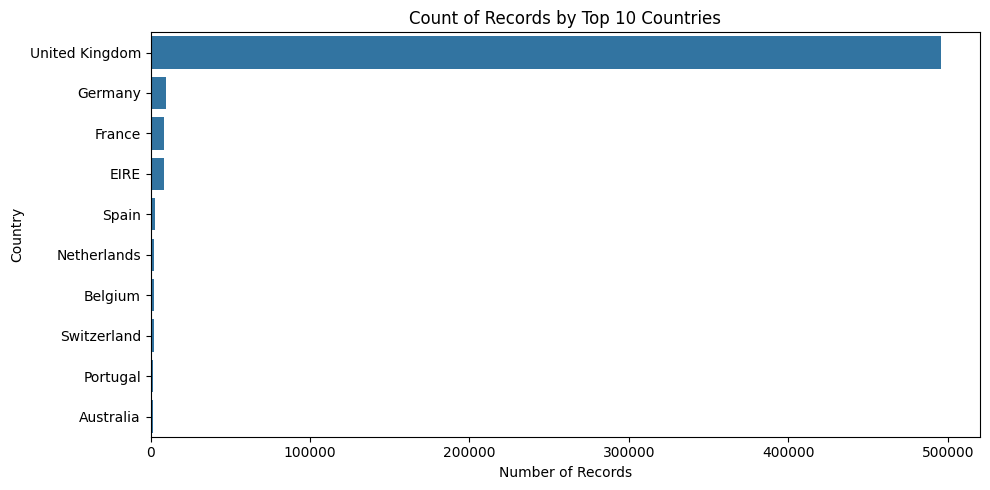

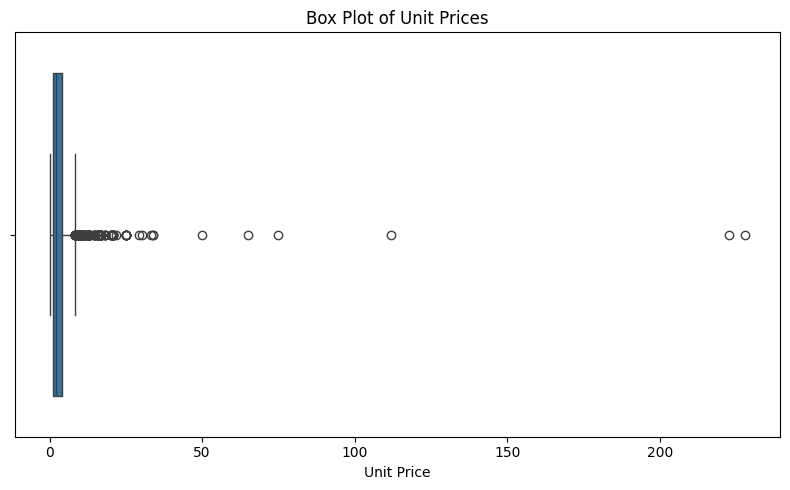

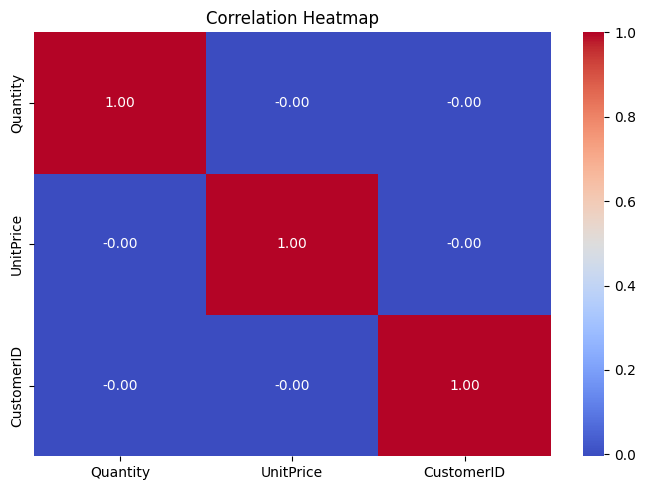

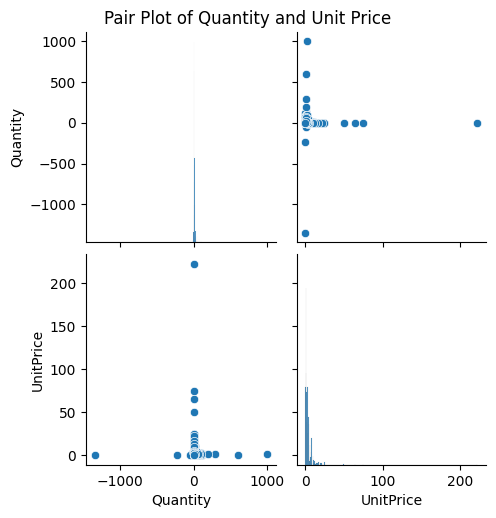

In [ ]:

# InternNova Week 4 - Task 6
# Data Visualization using Seaborn

import seaborn as sns
import matplotlib.pyplot as plt

# Use a sample to make plotting faster
sample_df = df.sample(n=min(3000, len(df)), random_state=42)

# 1. Count Plot: Top 10 countries
plt.figure(figsize=(10, 5))
top_countries = df["Country"].value_counts().head(10).index
sns.countplot(data=df[df["Country"].isin(top_countries)],
              y="Country",
              order=top_countries)
plt.title("Count of Records by Top 10 Countries")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# 2. Box Plot: Unit price distribution
plt.figure(figsize=(8, 5))
sns.boxplot(x=sample_df["UnitPrice"])
plt.title("Box Plot of Unit Prices")
plt.xlabel("Unit Price")
plt.tight_layout()
plt.show()


# 3. Heatmap: Correlation between numerical variables
numeric_df = df[["Quantity", "UnitPrice", "CustomerID"]].dropna()
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 4. Pair Plot: Relationships between numerical variables
pair_sample = df[["Quantity", "UnitPrice"]].dropna()
pair_sample = pair_sample.sample(n=min(1000, len(pair_sample)),
                                 random_state=42)

sns.pairplot(pair_sample)
plt.suptitle("Pair Plot of Quantity and Unit Price", y=1.02)
plt.show()


In [ ]:

# InternNova Week 4 - Task 7
# Inspect the dataset before cleaning

print("BEFORE CLEANING")
print("-" * 40)

print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst 5 rows before cleaning:")
display(df.head())


BEFORE CLEANING
----------------------------------------
Dataset shape: (541909, 9)

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0
Month,0



Duplicate rows: 5268

First 5 rows before cleaning:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12


In [ ]:

# Clean the dataset
# Keep the original dataset unchanged

df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove rows with missing values in important columns
df_clean = df_clean.dropna(
    subset=["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "Country"]
)

# Remove records with invalid negative unit prices
df_clean = df_clean[df_clean["UnitPrice"] >= 0]

print("Cleaning completed.")


Cleaning completed.


In [ ]:

print("AFTER CLEANING")
print("-" * 40)

print("Dataset shape:", df_clean.shape)

print("\nMissing values in each column:")
display(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nFirst 5 rows after cleaning:")
display(df_clean.head())


AFTER CLEANING
----------------------------------------
Dataset shape: (536639, 9)

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135035
Country,0
Month,0



Duplicate rows: 0

First 5 rows after cleaning:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12


Correlation Matrix:


,Quantity,UnitPrice
Quantity,1.000000,-0.001289
UnitPrice,-0.001289,1.000000


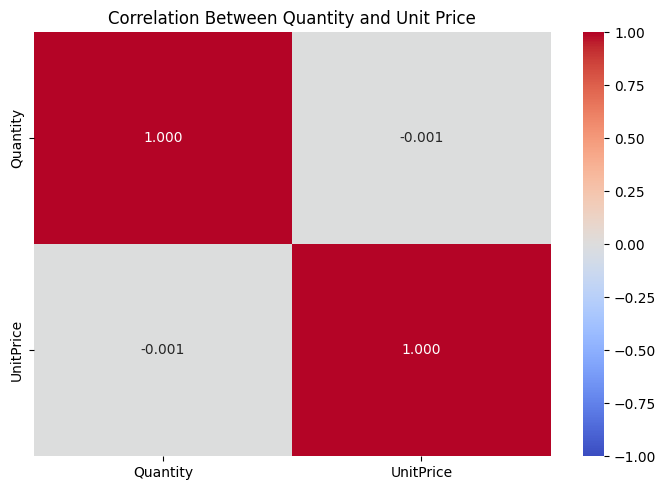

In [ ]:

# InternNova Week 4 - Task 8
# Correlation analysis using cleaned data

numeric_columns = ["Quantity", "UnitPrice"]

correlation_matrix = df_clean[numeric_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".3f")
plt.title("Correlation Between Quantity and Unit Price")
plt.tight_layout()
plt.show()


In [ ]:

# Generate data insights from the cleaned dataset

# Insight 1: Most frequently occurring product category
top_product = df_clean["Description"].mode().iloc[0]
print("Insight 1: Most frequent product description:", top_product)

# Insight 2: Country with the most records
top_country = df_clean["Country"].value_counts().idxmax()
country_count = df_clean["Country"].value_counts().max()
print("\nInsight 2: Country with the most records:", top_country)
print("Number of records:", country_count)

# Insight 3: Average unit price
average_price = df_clean["UnitPrice"].mean()
median_price = df_clean["UnitPrice"].median()
print("\nInsight 3: Average unit price:", round(average_price, 2))
print("Median unit price:", round(median_price, 2))

# Additional insight: Negative quantity records
negative_count = (df_clean["Quantity"] < 0).sum()
print("\nAdditional insight: Records with negative quantities:", negative_count)


Insight 1: Most frequent product description: WHITE HANGING HEART T-LIGHT HOLDER

Insight 2: Country with the most records: United Kingdom
Number of records: 490298

Insight 3: Average unit price: 4.67
Median unit price: 2.08

Additional insight: Records with negative quantities: 10587


1. Total recorded sales value: 9748131.07

2. Top 10 countries by recorded sales value:


,SalesValue
Country,
United Kingdom,8189252.30
Netherlands,284661.54
EIRE,262993.38
Germany,221509.47
France,197317.11
Australia,137009.77
Switzerland,56363.05
Spain,54756.03
Belgium,40910.96



3. Top 10 products by recorded sales value:


,SalesValue
Description,
DOTCOM POSTAGE,206245.48
REGENCY CAKESTAND 3 TIER,164459.49
WHITE HANGING HEART T-LIGHT HOLDER,99612.42
PARTY BUNTING,98243.88
JUMBO BAG RED RETROSPOT,92175.79
RABBIT NIGHT LIGHT,66661.63
POSTAGE,66230.64
PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
ASSORTED COLOUR BIRD ORNAMENT,58792.42



4. Records with negative quantities: 10587


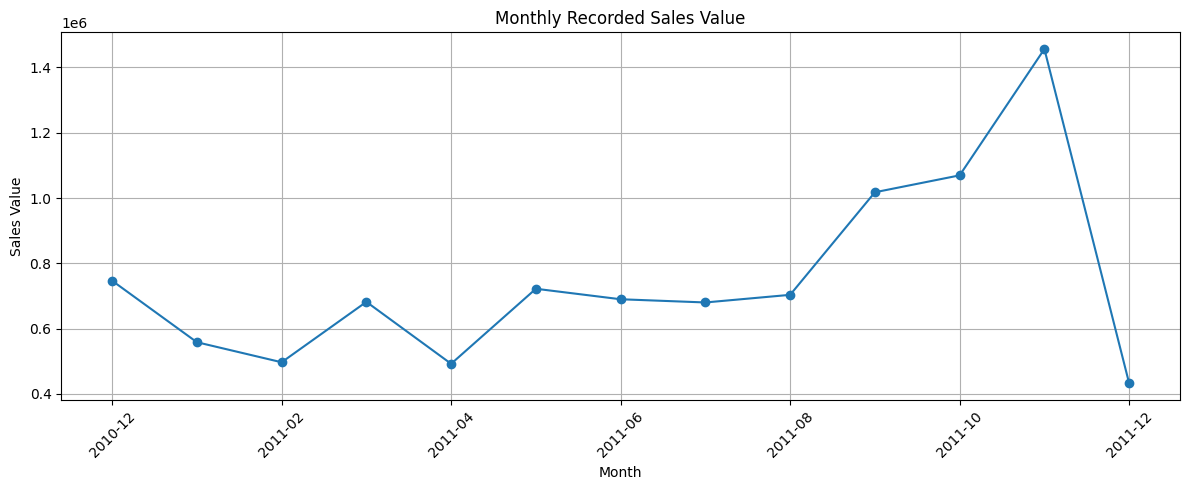

In [ ]:

# InternNova Week 4 - Task 9
# Business Recommendations based on data analysis

# Create a sales value column
df_clean["SalesValue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# 1. Total recorded sales value
total_sales = df_clean["SalesValue"].sum()
print("1. Total recorded sales value:", round(total_sales, 2))

# 2. Top 10 countries by recorded sales value
country_sales = (
    df_clean.groupby("Country")["SalesValue"]
    .sum()
    .sort_values(ascending=False)
)

print("\n2. Top 10 countries by recorded sales value:")
display(country_sales.head(10).round(2))

# 3. Top 10 product descriptions by recorded sales value
product_sales = (
    df_clean.groupby("Description")["SalesValue"]
    .sum()
    .sort_values(ascending=False)
)

print("\n3. Top 10 products by recorded sales value:")
display(product_sales.head(10).round(2))

# 4. Records with negative quantities
negative_records = (df_clean["Quantity"] < 0).sum()
print("\n4. Records with negative quantities:", negative_records)

# 5. Monthly recorded sales value
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M").astype(str)

monthly_sales = df_clean.groupby("Month")["SalesValue"].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Recorded Sales Value")
plt.xlabel("Month")
plt.ylabel("Sales Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()
